# 07 – So sánh tổng hợp các mô hình

Gộp kết quả mà các notebook 04–07 đã lưu trong `outputs/metrics/` (bảng baseline do `python main.py evaluate --family baseline` tạo). **Mọi mô hình dùng chung một phép chia train/test và cùng tập đánh giá.**

- Dự đoán rating: RMSE, MAE (thấp hơn tốt hơn).
- Top-N (K = 10): Precision, Recall, NDCG, HitRate (cao hơn tốt hơn). Phim liên quan = rating ≥ 4 trong tập test; ứng viên là mọi phim chưa xem trong train.
- Ngoài độ chính xác: Coverage (độ phủ catalog), Novelty (độ mới lạ), Diversity (đa dạng thể loại trong danh sách), tính trên Top-20.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # để import được package src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

from src.config import RESULTS_DIR
from src.experiment import load_experiment, make_validation, run_model, save_metrics
from src.evaluation.metrics import rmse

exp = load_experiment()                # cùng dữ liệu + cùng phép chia + cùng seed cho mọi notebook
FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print(f"train={len(exp.train):,}  test={len(exp.test):,}  users={len(exp.user2idx):,}  items={len(exp.item2idx):,}")

train=800,193  test=200,016  users=6,040  items=3,706


In [2]:
files = ["baseline", "knn", "mf", "content_hybrid", "deep"]
res = pd.concat([pd.read_csv(RESULTS_DIR / "metrics" / f"{f}.csv") for f in files], ignore_index=True)
res.to_csv(RESULTS_DIR / "metrics" / "all_models.csv", index=False)
print(len(res), "mô hình"); res.Family.value_counts()

18 mô hình


Family
Baseline                6
Matrix Factorization    4
Deep learning           3
Collaborative (kNN)     2
Content-based           2
Hybrid                  1
Name: count, dtype: int64

## Bảng 1 – Dự đoán rating (RMSE)

Trả lời câu hỏi: *mô hình đoán user sẽ chấm phim bao nhiêu sao, lệch thực tế bao nhiêu?* Tính trên mọi rating trong tập test; dự đoán được kẹp về [1, 5] trước khi tính.

**RMSE** (Root Mean Squared Error) – thấp hơn tốt hơn

$$\text{RMSE} = \sqrt{\frac{1}{N}\sum_{(u,i)\in\text{test}} (r_{ui} - \hat r_{ui})^2}$$

- Sai số trung bình theo đơn vị *sao*, nhưng **phạt nặng các lần đoán lệch nhiều** (do bình phương): lệch 2 sao một lần bị phạt bằng lệch 1 sao bốn lần.
- Mốc tham chiếu: GlobalMean (luôn đoán trung bình toàn cục ≈ 3.58) có RMSE ≈ 1.12. Mô hình nào không thấp hơn rõ mốc này là chưa học được gì.

**MAE** (Mean Absolute Error) – thấp hơn tốt hơn

$$\text{MAE} = \frac{1}{N}\sum_{(u,i)\in\text{test}} |r_{ui} - \hat r_{ui}|$$

- Sai số trung bình "thật", dễ diễn giải: MAE ≈ 0.66 nghĩa là trung bình đoán lệch khoảng 2/3 sao.
- Luôn có MAE ≤ RMSE. Khoảng cách RMSE − MAE càng lớn thì mô hình càng có nhiều lần đoán sai lớn.

**FitTime_s:** thời gian huấn luyện (giây). Không phản ánh chất lượng, nhưng quan trọng khi ứng dụng phải huấn luyện lại (ví dụ có user mới).

*Lưu ý:* các mô hình chỉ cho điểm xếp hạng (Popularity(count), ImplicitALS, NeuMF, BPR-MF) **không dự đoán rating** ở thang 1–5 (ví dụ NeuMF cho logit, có thể âm hoặc > 5) nên không có RMSE/MAE và bị loại khỏi bảng này.

In [3]:
t1 = res.dropna(subset=["RMSE"]).sort_values("RMSE")[["Model", "Family", "RMSE", "MAE", "FitTime_s"]]
t1.round(4).reset_index(drop=True)

,Model,Family,RMSE,MAE,FitTime_s
0,BiasedMF(f=200),Matrix Factorization,0.8597,0.6737,10.2794
1,Hybrid(MF+ItemKNN+Content),Hybrid,0.8660,0.6805,13.7893
2,PureSVD(f=30),Matrix Factorization,0.8824,0.6948,1.1592
3,AutoRec(h=300),Deep learning,0.8866,0.7015,2.5724
4,NMF(f=80),Matrix Factorization,0.9032,0.7092,0.9194
5,ContentBased(genres+title),Content-based,0.9042,0.7110,0.5567
6,ContentBased(genres),Content-based,0.9049,0.7123,0.8435
7,BiasBaseline,Baseline,0.9104,0.7209,0.2977
8,"ItemKNN(k=5,pearson)",Collaborative (kNN),0.9631,0.7308,0.6714
9,ItemMean,Baseline,0.9791,0.7815,0.0825


## Bảng 2 – Xếp hạng Top-10 (sắp theo NDCG@10)

Trả lời câu hỏi: *trong 10 phim gợi ý, có bao nhiêu phim user thật sự thích, và chúng nằm ở vị trí nào?* Đây là nhóm chỉ số quan trọng nhất với một hệ thống gợi ý.

**Quy ước tính** (`src/evaluation/metrics.py`):
- Danh sách gợi ý của user = các phim điểm cao nhất, **đã loại phim user chấm trong train**.
- Phim **liên quan** = phim trong tập test được user chấm **≥ 4** (`RELEVANT_RATING`).
- Precision/Recall/NDCG/HitRate lấy trung bình trên các user có ít nhất 1 phim liên quan trong test.

*Ví dụ dùng chung bên dưới:* user có **5** phim liên quan; danh sách 10 phim trúng ở **vị trí 1 và 4**.

**Precision@10** – tỉ lệ phim gợi ý đúng gu

$$\text{Precision@}K = \frac{\#\text{phim trúng trong top-}K}{K}$$

Ví dụ: 2/10 = **0.2**. Precision@10 ≈ 0.24 nghĩa là trung bình khoảng 2–3 trong 10 phim gợi ý là phim user đã xem và thích.

**Recall@10** – tỉ lệ phim yêu thích mà mô hình tìm ra được

$$\text{Recall@}K = \frac{\#\text{phim trúng trong top-}K}{\#\text{phim liên quan của user}}$$

Ví dụ: 2/5 = **0.4**. User có nhiều phim liên quan (ví dụ 100) thì Recall@10 tối đa chỉ 10/100 = 0.1, nên giá trị trung bình thường thấp.

**NDCG@10** (Normalized Discounted Cumulative Gain) – độ chính xác *có tính thứ tự*

$$\text{DCG@}K = \sum_{p=1}^{K} \frac{\text{hit}_p}{\log_2(p+1)}, \qquad \text{NDCG@}K = \frac{\text{DCG@}K}{\text{IDCG@}K}$$

- Trúng ở vị trí càng cao càng được nhiều điểm (trọng số 1, 0.63, 0.5, 0.43, … , 0.29 cho vị trí 1 → 10).
- IDCG là DCG lý tưởng (mọi phim liên quan xếp đầu danh sách, tối đa K phim), nên NDCG ∈ [0, 1].
- Ví dụ: DCG = 1 + 1/log₂5 = 1.431; IDCG = 1 + 0.631 + 0.5 + 0.431 + 0.387 = 2.949; NDCG = **0.485**.
- Là **chỉ số chính để chọn mô hình gợi ý**, vì người dùng thường chỉ xem vài phim đầu danh sách.

**HitRate@10** – tỉ lệ user được gợi ý trúng ít nhất 1 phim

$$\text{HitRate@}K = \frac{\#\text{user có} \ge 1 \text{ phim trúng trong top-}K}{\#\text{user}}$$

Ví dụ: user trên có giá trị **1**. HitRate@10 ≈ 0.8 nghĩa là 80% user nhận được ít nhất một gợi ý đúng gu; đây là chỉ số dễ giải thích nhất với người không chuyên.

*Lưu ý khi đọc:* phim user chưa từng xem bị tính là "không liên quan" dù có thể user sẽ thích, và test chỉ chứa 20% lịch sử của mỗi user. Vì vậy giá trị tuyệt đối **đánh giá thấp** mọi mô hình như nhau; nên dùng các chỉ số này để **so sánh tương đối** giữa các mô hình.

In [4]:
cols = ["Model", "Family", "Precision@10", "Recall@10", "NDCG@10", "HitRate@10", "Coverage@20", "Novelty@20", "Diversity@20"]
t2 = res.sort_values("NDCG@10", ascending=False)[cols]
t2.round(4).reset_index(drop=True)

,Model,Family,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@20,Novelty@20,Diversity@20
0,NeuMF(f=128),Deep learning,0.2477,0.1693,0.2946,0.8135,0.4107,2.6258,0.6380
1,BPR-MF(f=32),Deep learning,0.2293,0.1527,0.2711,0.7829,0.4903,2.6821,0.6355
2,ImplicitALS(f=32),Matrix Factorization,0.2054,0.1690,0.2502,0.8220,0.5316,2.9809,0.6152
3,Popularity(count),Baseline,0.1484,0.0862,0.1735,0.6064,0.0289,1.6693,0.7231
4,AutoRec(h=300),Deep learning,0.1472,0.0855,0.1726,0.5928,0.1754,2.3833,0.7205
5,PureSVD(f=30),Matrix Factorization,0.1032,0.0520,0.1262,0.4737,0.0988,2.8034,0.7886
6,Popularity(weighted),Baseline,0.0834,0.0485,0.1010,0.4603,0.0237,2.5522,0.7770
7,Hybrid(MF+ItemKNN+Content),Hybrid,0.0835,0.0503,0.1001,0.4618,0.2045,3.3630,0.6308
8,ContentBased(genres+title),Content-based,0.0715,0.0441,0.0875,0.4269,0.0982,3.3239,0.5514
9,ContentBased(genres),Content-based,0.0663,0.0404,0.0813,0.4071,0.0823,3.3312,0.5552


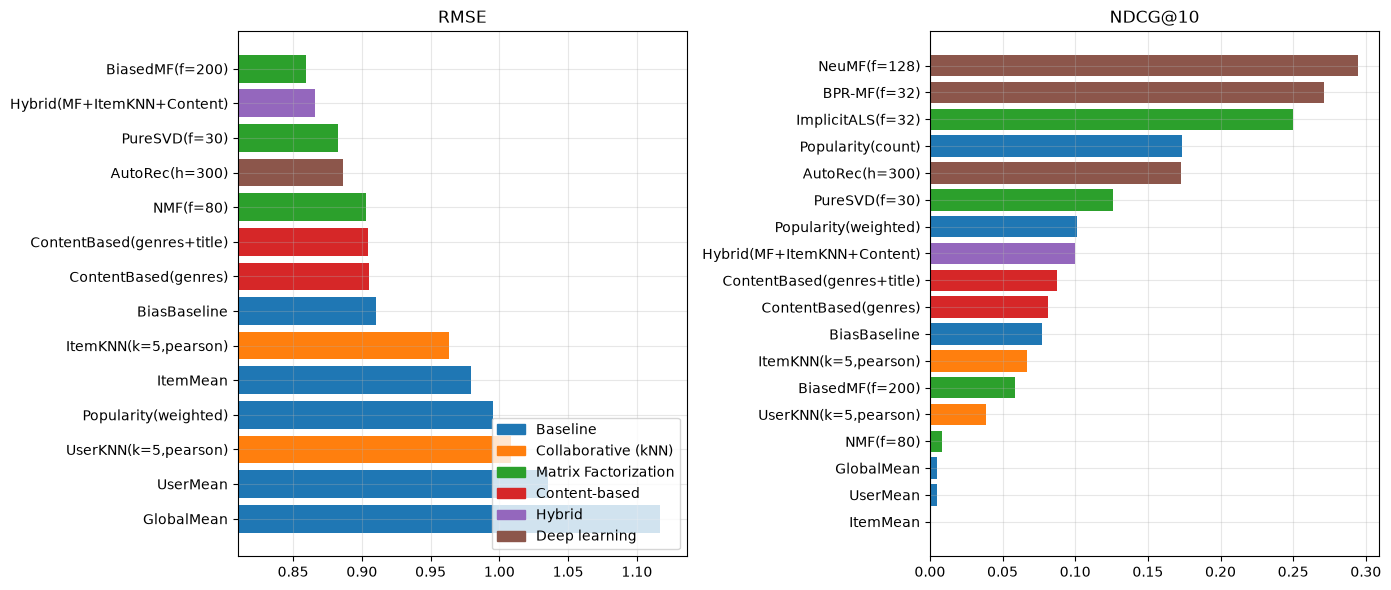

In [5]:
colors = dict(zip(res.Family.unique(), plt.cm.tab10.colors))
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
d = t1.iloc[::-1]; ax[0].barh(d.Model, d.RMSE, color=[colors[f] for f in d.Family]); ax[0].set(title="RMSE", xlim=(d.RMSE.min()-.05, d.RMSE.max()+.02))
d = t2.iloc[::-1]; ax[1].barh(d.Model, d["NDCG@10"], color=[colors[f] for f in d.Family]); ax[1].set(title="NDCG@10")
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "compare_rmse_ndcg.png"); plt.show()

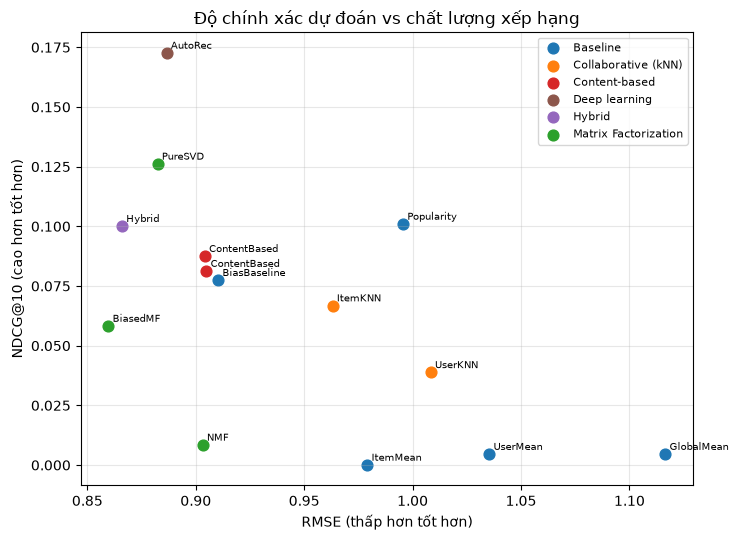

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
d = res.dropna(subset=["RMSE"])
for fam, g in d.groupby("Family"): ax.scatter(g.RMSE, g["NDCG@10"], s=60, label=fam, color=colors[fam])
for _, r in d.iterrows(): ax.annotate(r.Model.split("(")[0], (r.RMSE, r["NDCG@10"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="RMSE (thấp hơn tốt hơn)", ylabel="NDCG@10 (cao hơn tốt hơn)", title="Độ chính xác dự đoán vs chất lượng xếp hạng"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "compare_scatter.png"); plt.show()

## Ngoài độ chính xác: Coverage, Novelty, Diversity

Trả lời câu hỏi: *gợi ý có phong phú và đáng khám phá không, hay chỉ toàn phim bom tấn?* Tính trên danh sách **Top-20** của mọi user có trong test.

**Coverage@20** – độ phủ kho phim (cao hơn → dùng được nhiều phim hơn)

$$\text{Coverage@}K = \frac{\#\text{phim khác nhau xuất hiện trong danh sách của mọi user}}{\#\text{tổng số phim (3706)}}$$

- Popularity ≈ 0.03: mọi user nhận gần như cùng một danh sách (~100 phim). ItemKNN ≈ 0.84: gợi ý tới ~3.100 phim khác nhau.
- Coverage thấp nghĩa là phần lớn kho phim không bao giờ được gợi ý ("đuôi dài" bị bỏ quên).

**Novelty@20** – độ mới lạ (cao hơn → phim ít người biết hơn)

$$\text{Novelty@}K = \text{trung bình}\left[-\log_2 \text{pop}(i)\right], \qquad \text{pop}(i) = \frac{\#\text{user đã chấm phim } i \text{ (train)}}{\#\text{user}}$$

- Đổi ngược ra độ phổ biến trung bình: $\text{pop} \approx 2^{-\text{Novelty}}$. Novelty 2.4 → phim được ~19% user đã xem (phim nổi tiếng); Novelty 6.8 → ~0.9% (phim ít người biết).
- **Không phải cứ cao là tốt:** Novelty rất cao kèm NDCG gần 0 (ItemMean, NMF) nghĩa là mô hình gợi ý phim lạ *mà user không thích*. Novelty chỉ có giá trị khi độ chính xác vẫn ổn.

**Diversity@20** – đa dạng thể loại *bên trong một danh sách* (cao hơn → trộn nhiều thể loại)

$$\text{Diversity@}K = 1 - \frac{1}{K(K-1)} \sum_{i \ne j \in \text{top-}K} \cos(\mathbf{g}_i, \mathbf{g}_j)$$

với $\mathbf{g}_i$ là vector multi-hot 18 thể loại của phim $i$; lấy trung bình trên các user.
- ContentBased ≈ 0.55: gợi ý theo thể loại nên danh sách toàn phim cùng loại. BiasBaseline ≈ 0.79: danh sách trộn nhiều thể loại.
- Khác Coverage: Coverage đo đa dạng **giữa các user** (toàn hệ thống), Diversity đo đa dạng **trong danh sách của một user**.

**Đọc kết hợp các chỉ số:**

| Tình huống | Ý nghĩa |
|---|---|
| RMSE tốt nhưng NDCG thấp | Đoán sao giỏi trên phim user *đã xem* nhưng xếp hạng toàn kho kém (đẩy phim ít rating, điểm cao bất thường lên đầu) |
| NDCG cao, Novelty/Coverage thấp | Gợi ý trúng gu nhưng thiên về phim nổi tiếng – an toàn, ít bất ngờ |
| NDCG khá + Coverage cao | Cân bằng giữa trúng gu và khai thác đa dạng kho phim |
| Novelty rất cao, NDCG ≈ 0 | Gợi ý phim lạ nhưng vô dụng |

In [7]:
res.set_index("Model")[["Coverage@20", "Novelty@20", "Diversity@20"]].round(3).sort_values("Coverage@20", ascending=False)

,Coverage@20,Novelty@20,Diversity@20
Model,,,
"ItemKNN(k=5,pearson)",0.849,3.981,0.713
"UserKNN(k=5,pearson)",0.686,3.695,0.728
ImplicitALS(f=32),0.532,2.981,0.615
BPR-MF(f=32),0.490,2.682,0.635
BiasedMF(f=200),0.476,4.736,0.725
NMF(f=80),0.436,7.413,0.657
NeuMF(f=128),0.411,2.626,0.638
Hybrid(MF+ItemKNN+Content),0.205,3.363,0.631
UserMean,0.187,6.510,0.743


## Kết luận

*Số liệu từ lần huấn luyện lại trên GPU (RTX 4060, PyTorch CUDA); mọi mô hình trừ nhóm Baseline tính toán trên GPU. Siêu tham số của mọi mô hình (kể cả ImplicitALS, NeuMF, BPR-MF, trước đây không dò được vì không có RMSE) được chọn trên tập validation theo **NDCG@10**; RMSE chỉ còn là chỉ số tham khảo.*

- **Xếp hạng Top-N (tiêu chí chính):** các mô hình tối ưu cho xếp hạng/implicit thắng áp đảo: NeuMF f=128 (NDCG@10 ≈ 0.295) > BPR-MF f=32 (≈ 0.271) > Implicit ALS f=32 (≈ 0.250). Chúng vượt xa Popularity(count) (≈ 0.174). Thứ tự của các mô hình dẫn đầu (NeuMF > BPR-MF > ALS > AutoRec > PureSVD) trên validation và trên test trùng nhau, nên tiêu chí chọn nhất quán với kết quả cuối.
- **Tác động của việc đổi tiêu chí dò từ RMSE sang NDCG@10:**
  - Các mô hình dự đoán rating được dịch về phía xếp hạng: ItemKNN (k 100 → 5) NDCG 0.029 → 0.067, BiasedMF (f 20 → 200) 0.035 → 0.058, Hybrid (trọng số 0.5/0.4/0.1 → 0.3/0.1/0.6) 0.073 → 0.100. Đổi lại RMSE tăng: ItemKNN 0.864 → 0.963 (tệ hơn cả BiasBaseline 0.910), Hybrid 0.847 → 0.866.
  - NeuMF f 32 → 128 tăng NDCG 0.286 → 0.295; BPR-MF f 64 → 32 gần như giữ nguyên (0.273 → 0.271).
  - Dù đã dò theo NDCG, kNN, BiasedMF và Hybrid vẫn kém xa nhóm implicit: **hàm mục tiêu khi huấn luyện quan trọng hơn siêu tham số**.
- **Dự đoán rating (tham khảo):** tốt nhất là BiasedMF (RMSE ≈ 0.860), tiếp theo Hybrid (≈ 0.866) và PureSVD (≈ 0.882), đều vượt BiasBaseline (≈ 0.910) và GlobalMean (≈ 1.117). Nếu ứng dụng cần chức năng dự đoán số sao, nên dùng cấu hình chọn theo RMSE cho riêng chức năng đó.
- **Đánh đổi:** RMSE và NDCG xung đột trực tiếp, rõ nhất ở kNN (k lớn tốt cho RMSE, k nhỏ tốt cho NDCG). Giảm RMSE không đồng nghĩa gợi ý tốt hơn.
- **Độ phủ/đa dạng:** Popularity chỉ gợi ý ~2–3% catalog. BPR-MF và ImplicitALS đạt độ phủ ~49–53% với NDCG cao; NeuMF chính xác nhất, độ phủ ~41%. ItemKNN phủ rộng nhất (~85%) nhưng NDCG thấp.
- **Chi phí (GPU):** mọi mô hình huấn luyện dưới 14 giây; chậm nhất là Hybrid (≈ 13.8 s), NeuMF f=128 (≈ 12.0 s) và BiasedMF f=200 (≈ 10.3 s).
- **Chọn mô hình cho ứng dụng:** chức năng gợi ý Top-k dùng NeuMF (f=128), hoặc BPR-MF nếu muốn đa dạng hơn; chức năng dự đoán số sao cần mô hình cho rating thang 1–5 (BiasedMF hoặc Hybrid).
- *Lưu ý:*
  - Một số cấu hình tốt nhất nằm ở biên lưới dò: kNN k=5, BiasedMF f=200, NMF f=80, NeuMF f=128. Xu hướng là đơn điệu; lưới được dừng ở mức hợp lý về chi phí và kích thước mô hình.
  - Kết quả từ một lần chia train/test với seed cố định. Huấn luyện trên GPU không hoàn toàn tất định nên số liệu có thể dao động nhẹ ở chữ số thứ 3–4.